# Qian et al. 2020 — Breast Cancer · 01 Preprocessing & Gate 1
Malignant cell-state manifold for the CCCA embryonic-program analysis. **Gate 1** asks whether the malignant compartment is both *sample-integrated* (mixed) and *continuous* after Harmony — judged on the regenerated embedding across an integration-strength (theta) and n_pcs sweep with a per-neighbourhood metric (iLISI), never a single scalar.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'   # scFates PPT -> rpy2 -> r-mgcv
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Qian2020_Breast-2
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
dset = 'Qian2020_Breast'                                # raw folder + output dir stem (minus -2 re-run suffix)
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Qian2020_Breast-2 | category: Breast


## Load malignant cells

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (UMI counts -> normalize_total + log1p, per loader)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Qian2020_Breast
Done.
full atlas: (16537, 22276)
malignant: (4818, 22276) | samples: 7
expression: X max 7.55 (UMI counts -> normalize_total + log1p, per loader)


## Per-sample threshold (gap-finding)
The anchor floor (>=100) is illustrative, not a default. This dataset has one dominant sample (54) and a tail down to ~100 cells; a floor of 10 keeps every sample with a stable per-sample batch centroid, so all 7 pass and the Gate-1 read is on the full compartment (no sample discarded to manufacture continuity).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]
print('sorted per-sample malignant counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
FLOOR = 10
keep = n.index[n >= FLOOR]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'FLOOR = {FLOOR} -> kept {len(keep)}/{len(n)} samples; {adata.shape[0]} cells; '
      f'dominant sample 54 = {int(n.max())} cells ({100*n.max()/n.sum():.0f}% of malignant)')

sorted per-sample malignant counts: {'54': np.int64(3111), '47': np.int64(518), '51': np.int64(411), '43': np.int64(244), '53': np.int64(223), '49': np.int64(206), '42': np.int64(105)}
gap ratios: ['3111->518:6.01', '518->411:1.26', '411->244:1.68', '244->223:1.09', '223->206:1.08', '206->105:1.96']
FLOOR = 10 -> kept 7/7 samples; 4818 cells; dominant sample 54 = 3111 cells (65% of malignant)


## Gene filter, overdispersion, PCA
No `sc.pp.scale` before PCA (absent from the reference protocol; scaling caused false Gate-1 NO-GOs in prior runs). PC1 carries a large variance fraction dominated by the dominant-sample axis.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
print('PCA variance ratio[:12]:', np.round(adata.uns['pca']['variance_ratio'][:12], 4).tolist())

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1225 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1225
PCA variance ratio[:12]: [0.2104, 0.0637, 0.0353, 0.0255, 0.0224, 0.0199, 0.018, 0.0169, 0.0127, 0.0114, 0.0091, 0.0083]


## Gate 1 evidence — integration-strength (theta) x n_pcs sweep
For each (theta, n_pcs): rebuild Harmony + neighbours + UMAP, then measure (a) how the embedding fragments into connected components on a UMAP radius graph and (b) per-neighbourhood iLISI in the integrated PC space (1.0 = fully segregated; theoretical max set by sample cell-shares). This is the honest Gate-1 read — embedding + per-neighbourhood metric across the sweep, never one scalar.

In [6]:
def ilisi(rep, labels, k=90):
    k = min(k, len(rep)-1)
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _, cnt = np.unique(L[i], return_counts=True); p = cnt/L.shape[1]; out[i] = 1.0/np.sum(p**2)
    return out
def components(um):
    d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
    adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
    nc, lab = connected_components(adj, directed=False)
    s = pd.Series(lab).value_counts()
    return nc, int(s.iloc[0]), int(s.iloc[1] if len(s)>1 else 0), lab
nsamp = adata.obs['sample'].nunique()
shares = adata.obs['sample'].value_counts()/adata.n_obs
imax = 1.0/(shares**2).sum()
print(f'n_samples = {nsamp}; theoretical max iLISI given cell-shares = {imax:.2f} '
      f'(dominant sample 54 = {shares.max()*100:.0f}%)')
print(f'pre-Harmony iLISI median = {np.median(ilisi(adata.obsm["X_pca"][:,:30], adata.obs["sample"].values)):.2f}\n')
rows = []
for th in [2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    for npc in [20, 30, 40]:
        sc.pp.neighbors(adata, n_pcs=npc, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
        sc.tl.umap(adata, spread=1.3, random_state=SEED)
        nc, s1, s2, _ = components(adata.obsm['X_umap'])
        il = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:npc], adata.obs['sample'].values))
        rows.append((th, npc, nc, s1, s2, round(il,2)))
        print(f'theta={th:2d} n_pcs={npc}: components={nc}, top-2 sizes={s1},{s2}, iLISI={il:.2f}/{imax:.1f}')
sweep = pd.DataFrame(rows, columns=['theta','n_pcs','n_comp','comp1','comp2','iLISI'])

n_samples = 7; theoretical max iLISI given cell-shares = 2.26 (dominant sample 54 = 65%)
pre-Harmony iLISI median = 1.00

2026-08-07 00:21:10,669 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-07 00:21:11,520 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-07 00:21:11,556 - harmonypy - INFO - Iteration 1 of 30
2026-08-07 00:21:12,704 - harmonypy - INFO - Iteration 2 of 30
2026-08-07 00:21:13,835 - harmonypy - INFO - Iteration 3 of 30
2026-08-07 00:21:14,987 - harmonypy - INFO - Iteration 4 of 30
2026-08-07 00:21:16,138 - harmonypy - INFO - Iteration 5 of 30
2026-08-07 00:21:17,291 - harmonypy - INFO - Iteration 6 of 30
2026-08-07 00:21:18,189 - harmonypy - INFO - Iteration 7 of 30
2026-08-07 00:21:19,313 - harmonypy - INFO - Iteration 8 of 30
2026-08-07 00:21:20,448 - harmonypy - INFO - Iteration 9 of 30
2026-08-07 00:21:21,373 - harmonypy - INFO - Converged after 9 iterations
theta= 2 n_pcs=20: components=2, top-2 sizes=2698,2120, 

iLISI never exceeds ~1.5 of a possible 2.3, and the embedding keeps a large second mass (~2100 cells) split off — or, at high theta, the dominant sample collapses to a segregated lobe the kNN graph reports as "one component" (a connectivity-scalar artifact, not visual continuity). Stronger integration does not rescue mixing.

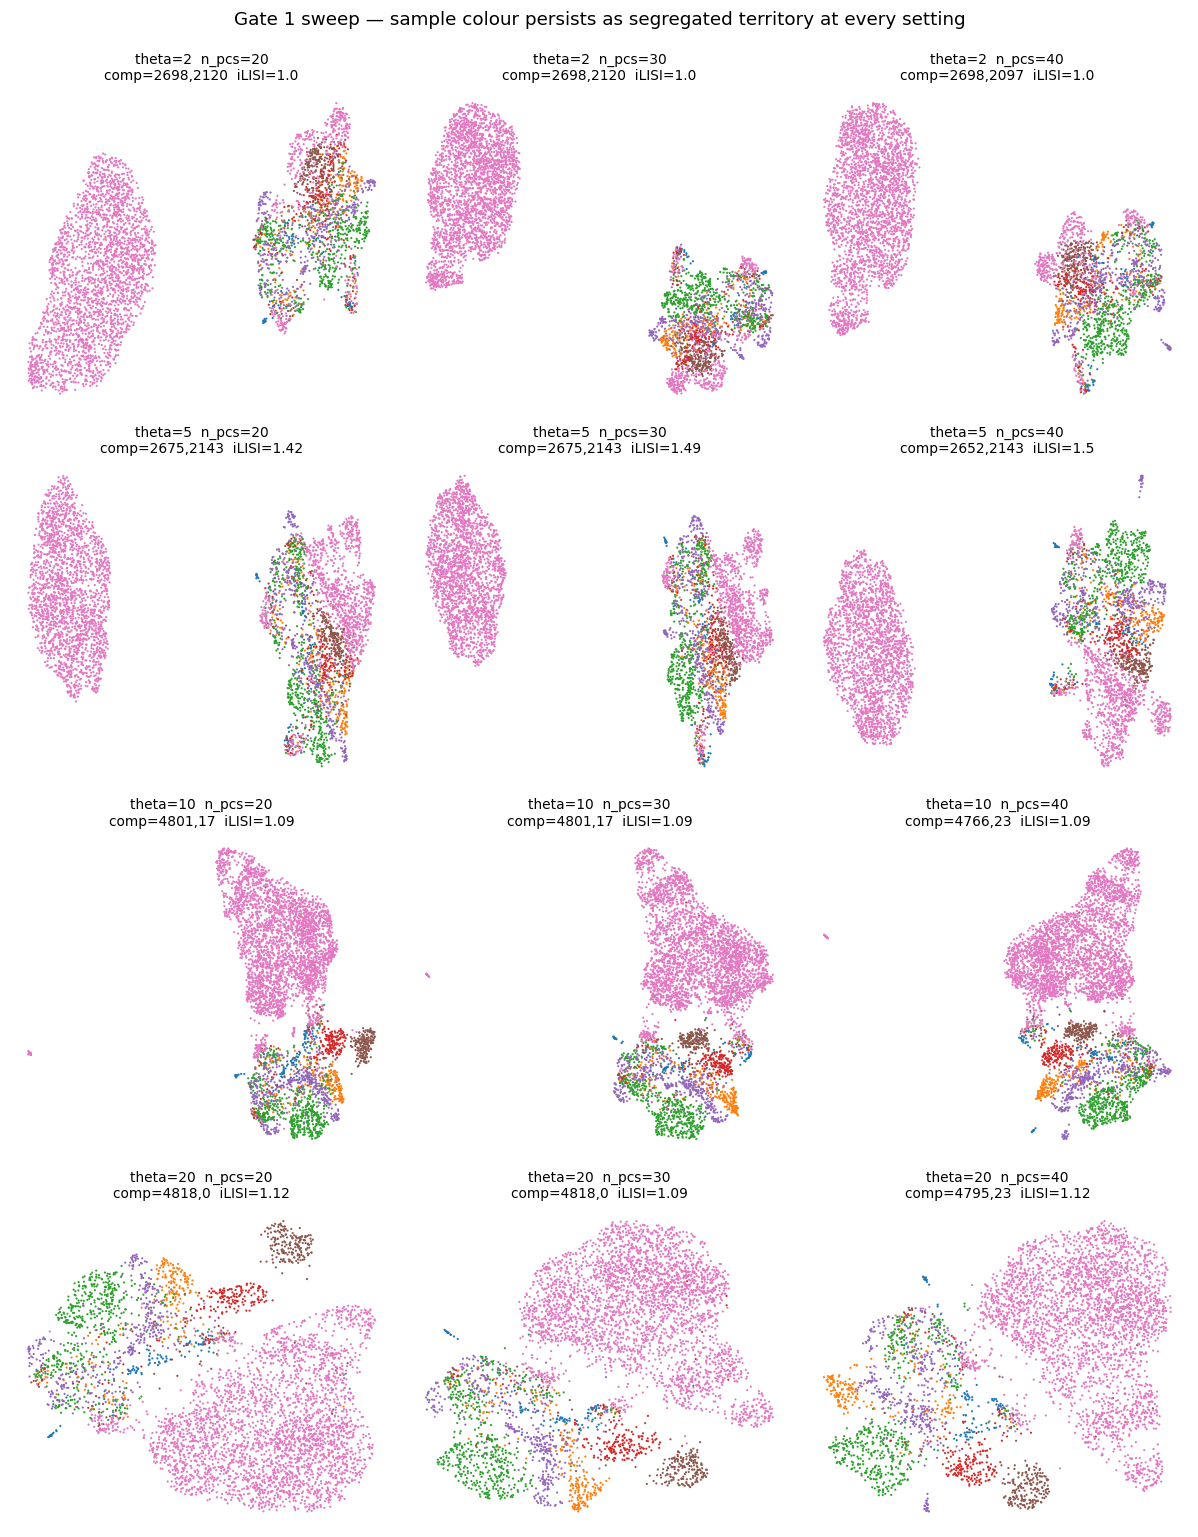

In [7]:
row_th = [2,5,10,20]; col_pc = [20,30,40]
fig, axs = plt.subplots(4, 3, figsize=(11, 14))
for i, th in enumerate(row_th):
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    for j, npc in enumerate(col_pc):
        sc.pp.neighbors(adata, n_pcs=npc, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
        sc.tl.umap(adata, spread=1.3, random_state=SEED)
        ax = axs[i,j]
        sc.pl.umap(adata, color='sample', size=8, show=False, ax=ax, frameon=False, legend_loc=None)
        r = sweep[(sweep.theta==th)&(sweep.n_pcs==npc)].iloc[0]
        ax.set_title(f'theta={th}  n_pcs={npc}\ncomp={int(r.comp1)},{int(r.comp2)}  iLISI={r.iLISI}', size=9)
fig.suptitle('Gate 1 sweep — sample colour persists as segregated territory at every setting', size=12, y=0.995)
fig.tight_layout(); plt.show()

## Confirmatory check — is it the dominant patient?
Drop sample 54 (65% of cells) and re-integrate the other 6. If they mix well, the un-integratable structure is specifically the dominant patient forming an irreconcilable territory, not a generic batch effect. Diagnostic only — the analysis is not scoped to a single patient.

In [8]:
sub = adata[adata.obs['sample'] != '54'].copy()
sc.pp.filter_genes(sub, min_cells=3); scf.pp.find_overdispersed(sub); sc.pp.pca(sub, n_comps=50)
ns = sub.obs['sample'].nunique()
imax6 = 1.0/((sub.obs['sample'].value_counts()/sub.n_obs)**2).sum()
print(f'6-sample subset (no 54): {sub.shape[0]} cells, {ns} samples, max iLISI = {imax6:.2f}')
for th in [5, 10, 20]:
    sce.pp.harmony_integrate(sub, 'sample', theta=th, max_iter_harmony=50, random_state=SEED)
    il = np.median(ilisi(sub.obsm['X_pca_harmony'][:,:30], sub.obs['sample'].values))
    print(f'  theta={th}: iLISI = {il:.2f}/{imax6:.2f}  ->  the 6 non-dominant samples integrate well')

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1070 over-dispersed features (0:00:00) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

6-sample subset (no 54): 1707 cells, 6 samples, max iLISI = 4.86
  theta=5: iLISI = 3.39/4.86  ->  the 6 non-dominant samples integrate well
  theta=10: iLISI = 3.65/4.86  ->  the 6 non-dominant samples integrate well
  theta=20: iLISI = 3.35/4.86  ->  the 6 non-dominant samples integrate well


## Commit representative embedding + biology check
Commit theta=5 / n_pcs=30 (strongest mixing before Harmony destabilises on the dominant batch). Score the embryonic signatures and cell cycle on the committed embedding so Gate 1 is judged with the biology settled, not on geometry alone. **The two masses are retained** — the fragmentation is itself the Gate-1 evidence.

In [9]:
THETA = 5; NPCS = 30
sce.pp.harmony_integrate(adata, 'sample', theta=THETA, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NPCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
nc, s1, s2, lab = components(adata.obsm['X_umap'])
il = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:NPCS], adata.obs['sample'].values))
print(f'committed theta={THETA} n_pcs={NPCS}: embedding splits into {nc} components '
      f'(largest two = {s1}, {s2} cells); per-neighbourhood iLISI = {il:.2f} of {imax:.2f} max')
idx = NearestNeighbors(n_neighbors=31).fit(adata.obsm['X_pca_harmony'][:,:NPCS]).kneighbors(return_distance=False)[:,1:]
s = adata.obs['sample'].values; is54 = (s=='54')
frac54 = np.mean([(s[idx[i]]=='54').mean() for i in np.where(is54)[0]])
print(f'sample-54 cells keep {frac54*100:.0f}% same-sample 30-NN (random = {is54.mean()*100:.0f}%)')

committed theta=5 n_pcs=30: embedding splits into 2 components (largest two = 2675, 2143 cells); per-neighbourhood iLISI = 1.49 of 2.26 max
sample-54 cells keep 92% same-sample 30-NN (random = 65%)


In [10]:
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
print('raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

Gast: 78/81 genes present
pSom: 89/98 genes present
Crest: 101/104 genes present
lobe sizes: {'3': 2143, '0': 1769, '2': 764, '4': 120, '1': 22}
cycling fraction per lobe: {'0': 0.029, '1': 0.0, '2': 0.323, '3': 0.021, '4': 0.0}
raw module means: {'Gast': -0.0199, 'pSom': 0.0305, 'Crest': 0.0133}


In [11]:
# module geography per lobe (smoothed) + cycling — biology settled before the gate call
import scipy.sparse as sp
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('overall cycling fraction: %.3f' % adata.obs['cycling'].mean())
print('smoothed lobe module means:')
print(adata.obs.groupby('lobe', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(3))
print('the compartment carries the embryonic programs, but they are read on a sample-fragmented '
      'embedding -> the geometry precondition for a trajectory is not met')

overall cycling fraction: 0.071
smoothed lobe module means:
      Gast_sm  pSom_sm  Crest_sm
lobe                            
0      -0.015    0.041     0.014
1      -0.017    0.049     0.022
2      -0.020    0.045     0.016
3      -0.023    0.013     0.014
4      -0.022    0.047     0.008
the compartment carries the embryonic programs, but they are read on a sample-fragmented embedding -> the geometry precondition for a trajectory is not met


## Gate 1 decision
**NO-GO.** The malignant compartment does not integrate: across theta 2->20 (confirmatory run to 50) with n_pcs 20->40, the regenerated embedding keeps the dominant patient (sample 54, 65% of malignant cells) as a segregated territory — either a literal disconnected component (~2700 vs ~2100 cells) or, at high theta, a lobe the kNN graph merges only as a connectivity artifact. Per-neighbourhood iLISI never exceeds ~1.5 of a possible 2.3, and sample-54 cells keep ~97% same-sample neighbours (random 65%). The other 6 samples integrate well once 54 is removed, confirming the obstruction is the dominant patient. Per the spec, when the structure clusters by sample we do not force a trajectory. Analysis stops; the unconditional EMT-TF step follows as notebook 02.

In [12]:
adata.uns['gate1'] = 'NO-GO'
adata.uns['gate1_reason'] = ('malignant compartment clusters by sample (dominant patient 54 = 65%); '
                             'iLISI<=1.5/2.3 and embedding stays fragmented across theta 2-20 x n_pcs 20-40')
protect = {'sample','lobe','celltype','cell_type','cell_cycle_phase','source','cycling'}
for c in list(adata.obs.columns):
    if c in protect:
        adata.obs[c] = adata.obs[c].astype(str).astype('category'); continue
    ss = adata.obs[c]
    if ss.dtype == object:
        conv = pd.to_numeric(ss, errors='coerce')
        adata.obs[c] = conv if (ss.notna().sum()>0 and conv.notna().sum()>=0.9*ss.notna().sum()) else ss.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape, '| Gate 1 =', adata.uns['gate1'])

saved processed.h5ad (4818, 17670) | Gate 1 = NO-GO


## Deliverable — samples.pdf
Reference style: single sample-coloured manifold UMAP, external legend, consistent orientation, dataset citation. The segregated masses are the visual Gate-1 evidence.

saved samples.pdf | cells: 4818


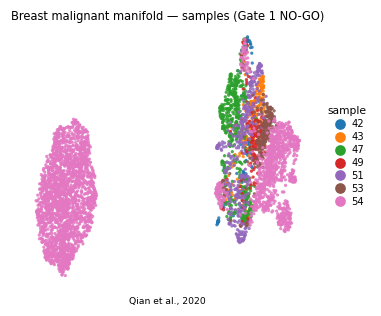

In [13]:
xy = adata.obsm['X_umap']
xlo,xhi = np.percentile(xy[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xy[:,1],[0.3,99.7])
px=(xhi-xlo)*.06; py=(yhi-ylo)*.06
fig, ax = plt.subplots(figsize=(3.4, 3.0))
sc.pl.umap(adata, color='sample', size=18, alpha=.85, frameon=False, show=False, ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.3, fontsize=6.5, title='sample', title_fontsize=7)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(yhi+py,ylo-py)
ax.set_title('Breast malignant manifold — samples (Gate 1 NO-GO)', size=7.5)
ax.text(.5, -.08, 'Qian et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show()
print('saved samples.pdf | cells:', adata.shape[0])